In [1]:
# importing libraries
import os
os.environ["OMP_NUM_THREADS"] = "1"
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# loading Iris data
from sklearn.datasets import load_iris

In [3]:
# converting data to DataFrame
data=load_iris()
df=pd.DataFrame(data.data,columns=data.feature_names)
df['target']=data.target

In [4]:
# Inspecting data
df.head(5)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [5]:
# checking for missing values
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

From the above, it shows that there are no missing values in the dataset

In [6]:
# providing the descriptive statistics of the data
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


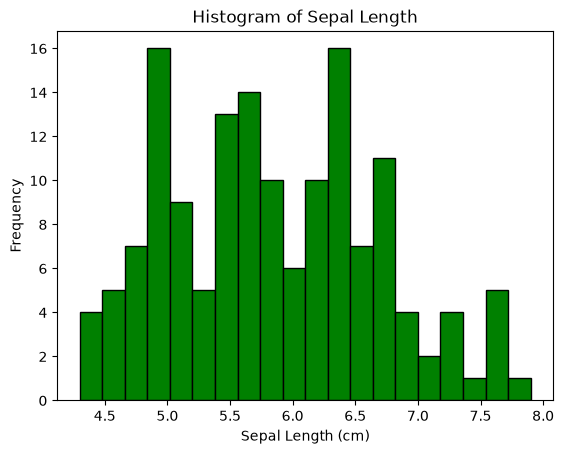

In [7]:
plt.hist(df['sepal length (cm)'], bins=20, color='green', edgecolor='black')
plt.title('Histogram of Sepal Length')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Frequency')
plt.show()

In [8]:
# Standardising the features
from sklearn.preprocessing import StandardScaler
features = df.drop('target', axis=1)
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)
scaled_df = pd.DataFrame(scaled_features, columns=features.columns)
scaled_df['target'] = df['target']
print(scaled_df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0          -0.900681          1.019004          -1.340227         -1.315444   
1          -1.143017         -0.131979          -1.340227         -1.315444   
2          -1.385353          0.328414          -1.397064         -1.315444   
3          -1.506521          0.098217          -1.283389         -1.315444   
4          -1.021849          1.249201          -1.340227         -1.315444   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


In [9]:
# splitting the data into training and testing
from sklearn.model_selection import train_test_split

X = df.drop('target', axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=45)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)


Training set shape: (120, 4)
Testing set shape: (30, 4)


In [10]:
# building logistic Regression classification model
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model = LogisticRegression(max_iter=200) 

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


Accuracy: 0.9666666666666667

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       0.88      1.00      0.93         7
           2       1.00      0.92      0.96        12

    accuracy                           0.97        30
   macro avg       0.96      0.97      0.96        30
weighted avg       0.97      0.97      0.97        30

Confusion Matrix:
 [[11  0  0]
 [ 0  7  0]
 [ 0  1 11]]


## K-Means Clustering

K-Means clustering is an unsupervised machine learning algorithm that groups observations into a specified number of clusters based on their similarity.

Unlike the Logistic Regression model, K-Means does not use the target variable when forming clusters. The goal is to identify natural groupings within the Iris observations.

In [11]:
from sklearn.cluster import KMeans

In [12]:
inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=45, n_init=10)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

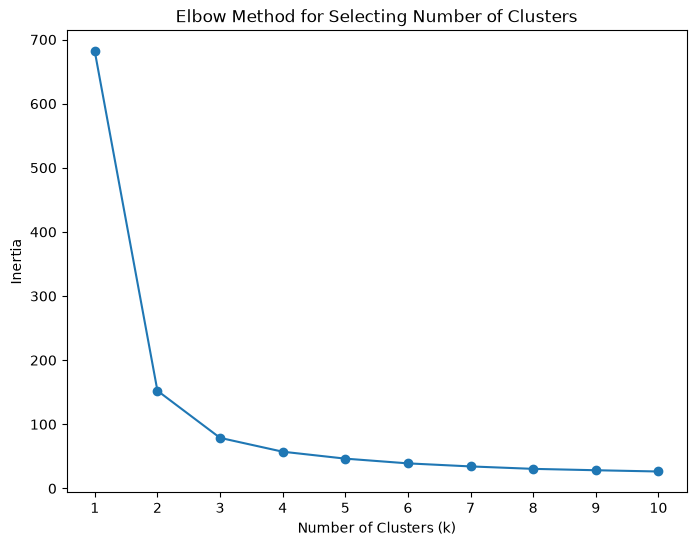

In [13]:
plt.figure(figsize=(8, 6))

plt.plot(range(1, 11), inertia, marker='o')

plt.title('Elbow Method for Selecting Number of Clusters')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.show()

### Selecting the Number of Clusters

The Elbow Method was used to examine different values of k. As the number of clusters increases, the within-cluster variation decreases. The point where the reduction in inertia begins to level off provides an indication of a suitable number of clusters which is 3.

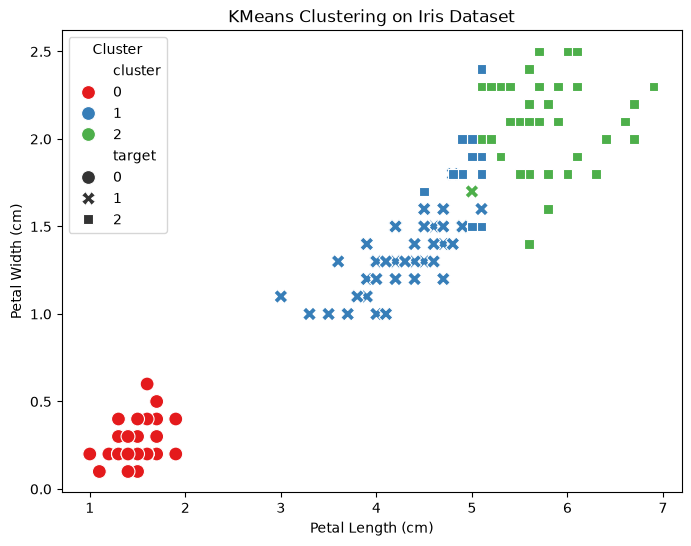

In [14]:
X = df.drop('target', axis=1)
kmeans = KMeans(n_clusters=3, random_state=45, n_init=10)
df['cluster'] = kmeans.fit_predict(X)
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x='petal length (cm)',
    y='petal width (cm)',
    hue='cluster',
    palette='Set1',
    style='target', 
    s=100
)
plt.title('KMeans Clustering on Iris Dataset')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.legend(title='Cluster')
plt.show()


## Principal Component Analysis (PCA)

Principal Component Analysis (PCA) is a dimensionality reduction technique used to transform a dataset with many features into a smaller number of principal components while retaining as much of the original information as possible.

The Iris dataset contains four numerical features. In this section, PCA is used to reduce these four features to two principal components so that the data can be visualized in two dimensions.

In [15]:
from sklearn.decomposition import PCA

In [16]:
X = df.drop(['target', 'cluster'], axis=1, errors='ignore')
y = df['target']
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)


In [17]:
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.92461872 0.05306648]
Total explained variance: 0.9776852063187922


The explained variance ratio shows the proportion of the dataset's variability captured by each principal component. The total explained variance indicates how much of the information contained in the original four features is retained after reducing the dataset to two dimensions.

In [18]:
## Creating the PCA DataFrame
pca_df = pd.DataFrame(
    X_pca,
    columns=['Principal Component 1', 'Principal Component 2']
)

pca_df['target'] = y.values

pca_df.head()

,Principal Component 1,Principal Component 2,target
0,-2.684126,0.319397,0
1,-2.714142,-0.177001,0
2,-2.888991,-0.144949,0
3,-2.745343,-0.318299,0
4,-2.728717,0.326755,0


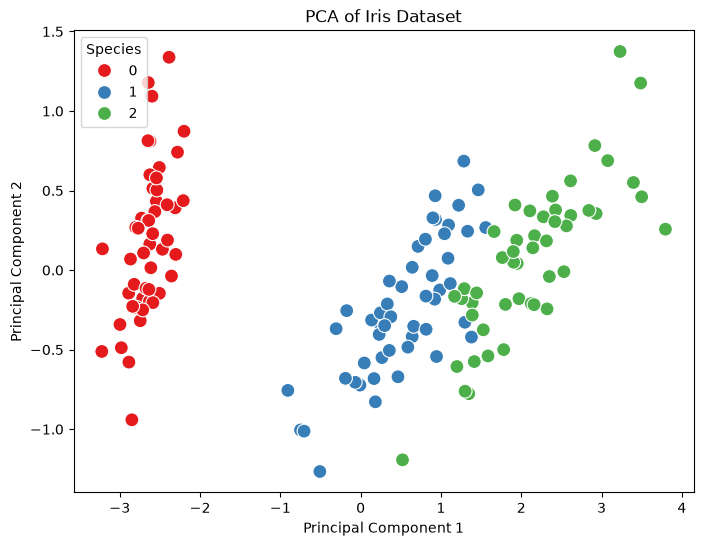

In [19]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=pca_df,
    x='Principal Component 1',
    y='Principal Component 2',
    hue='target',
    palette='Set1',
    s=100
)

plt.title('PCA of Iris Dataset')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Species')
plt.show()

The scatter plot shows the Iris observations after reducing the original four features to two principal components. The visualization helps illustrate how well the observations belonging to different species can be separated in the reduced two-dimensional space.